# Phase 4 — Non-Linear Model Exploration: Decision Trees & Random Forests

## 1. System Architecture & Objectives
This notebook evaluates non-linear, tree-based learning architectures against our benchmark OLS regression model. Standard linear estimators assume fixed global slopes across the entire state of California, which fails to capture local thresholds and feature interactions (such as the compounding value of square footage when paired with high bathroom counts).

### Core Objectives
* **Ingest Modeling Artifacts**: Load the preprocessed arrays (`X_train_processed.npy`, `y_train.npy`, `X_test_processed.npy`, `y_test.npy`) and baseline benchmark scorecard (`baseline_benchmark_metrics.csv`).
* **Train Single Decision Tree**: Fit a regularized `DecisionTreeRegressor` to establish how recursive, orthogonal binary splits perform without ensemble averaging.
* **Train Random Forest Ensemble**: Fit a `RandomForestRegressor` with bootstrap aggregation (bagging) and randomized feature sub-sampling to reduce variance and mitigate single-tree overfitting.
* **Unified Model Comparison**: Tabulate out-of-sample performance across all candidate architectures on identical evaluation metrics:
  * **$R^2$ Score**: Macro variance explained.
  * **MdAPE (%)**: Headline robust median percentage miss.
  * **MAPE (%)**: Mean relative error.
  * **MAE ($)**: Dollar-denominated mean miss.
* **Feature Importance Evaluation**: Extract and compare tree impurity reduction (MDI) against linear model standardized weights to observe how feature relevance shifts in non-linear spaces.
* **Error Tier Diagnostics**: Evaluate localized performance across housing price quintiles to observe whether ensemble averaging resolves high-tier heteroscedasticity.
* **Artifact Registration**: Persist the best-performing ensemble model and update the comparative performance ledger.

In [1]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

# Configure display and visual styling
pd.set_option("display.float_format", lambda x: "%.4f" % x)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

print("Dependencies loaded successfully.")

Dependencies loaded successfully.


## 2. Ingestion of Preprocessed Matrices & Baseline Benchmark

We load the normalized input arrays and the locked baseline metrics scorecard from `artifacts/`.

In [2]:
artifacts_dir = Path("artifacts")

# Load processed numeric arrays
X_train = np.load(artifacts_dir / "X_train_processed.npy")
X_test = np.load(artifacts_dir / "X_test_processed.npy")
y_train = np.load(artifacts_dir / "y_train.npy")
y_test = np.load(artifacts_dir / "y_test.npy")

# Canonical feature names
FEATURE_NAMES = [
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt"
]

# Load baseline scorecard
baseline_metrics_df = pd.read_csv(artifacts_dir / "baseline_benchmark_metrics.csv")

print("--- Data Contract Verification ---")
print(f"X_train: {X_train.shape[0]:,} rows × {X_train.shape[1]} features")
print(f"X_test : {X_test.shape[0]:,} rows × {X_test.shape[1]} features")
print("\n--- OLS Benchmark Metrics ---")
display(baseline_metrics_df)

--- Data Contract Verification ---
X_train: 293,758 rows × 5 features
X_test : 12,336 rows × 5 features

--- OLS Benchmark Metrics ---


,Evaluation Metric,In-Sample (Train),Out-of-Sample (Test Cutoff)
0,R² Score,0.4423,0.4621
1,MdAPE (%),31.7127,31.0857
2,MAPE (%),46.2933,46.1184
3,MAE ($),456857.8629,464862.7786


## 3. Estimator 1: Regularized Decision Tree Regressor

A single decision tree recursively partitions the feature space into orthogonal hyper-rectangles by minimizing Mean Squared Error (variance reduction).

### Regularization Constraints
To prevent the tree from memorizing training observations into leaf nodes containing single properties, we apply structural constraints:
* `max_depth=10`: Restricts interaction hierarchy to avoid deep tail memorization.
* `min_samples_leaf=20`: Requires each terminal leaf node to aggregate at least 20 historical transactions to ensure statistical support for price predictions.
* `random_state=42`: Enforces exact reproducibility of split selection.

In [3]:
# Instantiate and fit Decision Tree
dt_reg = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

dt_reg.fit(X_train, y_train)

# Generate predictions
y_train_pred_dt = dt_reg.predict(X_train)
y_test_pred_dt = dt_reg.predict(X_test)

print("DecisionTreeRegressor trained successfully.")
print(f"Tree Depth: {dt_reg.get_depth()}, Leaf Nodes: {dt_reg.get_n_leaves():,}")

DecisionTreeRegressor trained successfully.
Tree Depth: 10, Leaf Nodes: 772


## 4. Estimator 2: Random Forest Ensemble Regressor

Random Forest builds an ensemble of decorrelated decision trees using two layers of stochastic randomization:
1. **Bootstrap Aggregation (Bagging)**: Each tree trains on an independent bootstrap sample of the training dataset.
2. **Feature Sub-sampling**: At each split, only a subset of features is evaluated, preventing dominant features (like `LivingArea`) from dictating every initial partition across all trees.

Averaging the predictions across multiple trees ($\hat{y}_{\text{RF}} = \frac{1}{B} \sum_{b=1}^B \hat{y}_b$) significantly reduces variance without inflating bias.

In [4]:
# Instantiate and fit Random Forest
rf_reg = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_reg.fit(X_train, y_train)

# Generate predictions
y_train_pred_rf = rf_reg.predict(X_train)
y_test_pred_rf = rf_reg.predict(X_test)

print("RandomForestRegressor trained successfully across 100 estimators.")

RandomForestRegressor trained successfully across 100 estimators.


## 5. Comprehensive Model Comparison Ledger

We consolidate out-of-sample test results across all three architectures into a unified comparison ledger to evaluate whether non-linear modeling delivers tangible, statistically significant lift over the linear baseline.

--- Unified Out-of-Sample Evaluation Ledger ---


,Model Architecture,Train R²,Test R²,Test MdAPE (%),Test MAPE (%),Test MAE ($)
0,Linear Regression (Baseline),0.4423,0.4621,31.0857,46.1184,464862.7786
1,Decision Tree (max_depth=10),0.5337,0.5158,28.5779,40.7844,430262.3053
2,Random Forest (100 trees),0.5961,0.5399,27.1097,39.2702,415255.0228


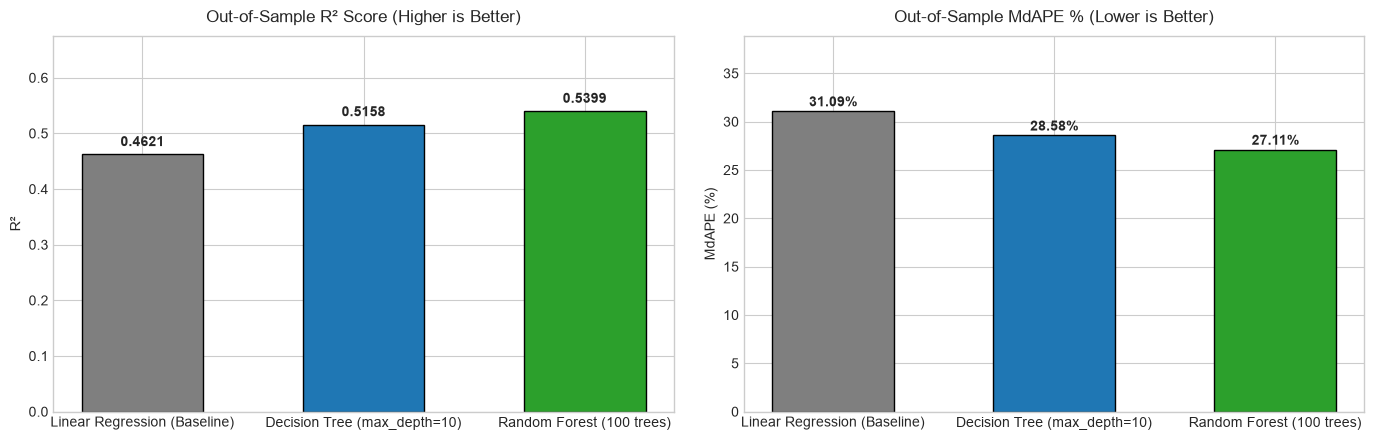

In [5]:
def compute_mdape(y_true, y_pred):
    """Calculates Median Absolute Percentage Error."""
    return float(np.median(np.abs((y_true - y_pred) / y_true)) * 100)

# Pull baseline test metrics
baseline_test_r2 = baseline_metrics_df.loc[baseline_metrics_df["Evaluation Metric"] == "R² Score", "Out-of-Sample (Test Cutoff)"].values[0]
baseline_test_mdape = baseline_metrics_df.loc[baseline_metrics_df["Evaluation Metric"] == "MdAPE (%)", "Out-of-Sample (Test Cutoff)"].values[0]
baseline_test_mape = baseline_metrics_df.loc[baseline_metrics_df["Evaluation Metric"] == "MAPE (%)", "Out-of-Sample (Test Cutoff)"].values[0]
baseline_test_mae = baseline_metrics_df.loc[baseline_metrics_df["Evaluation Metric"] == "MAE ($)", "Out-of-Sample (Test Cutoff)"].values[0]

# Construct comparison table
comparison_records = [
    {
        "Model Architecture": "Linear Regression (Baseline)",
        "Train R²": baseline_metrics_df.loc[baseline_metrics_df["Evaluation Metric"] == "R² Score", "In-Sample (Train)"].values[0],
        "Test R²": baseline_test_r2,
        "Test MdAPE (%)": baseline_test_mdape,
        "Test MAPE (%)": baseline_test_mape,
        "Test MAE ($)": baseline_test_mae
    },
    {
        "Model Architecture": "Decision Tree (max_depth=10)",
        "Train R²": r2_score(y_train, y_train_pred_dt),
        "Test R²": r2_score(y_test, y_test_pred_dt),
        "Test MdAPE (%)": compute_mdape(y_test, y_test_pred_dt),
        "Test MAPE (%)": mean_absolute_percentage_error(y_test, y_test_pred_dt) * 100,
        "Test MAE ($)": mean_absolute_error(y_test, y_test_pred_dt)
    },
    {
        "Model Architecture": "Random Forest (100 trees)",
        "Train R²": r2_score(y_train, y_train_pred_rf),
        "Test R²": r2_score(y_test, y_test_pred_rf),
        "Test MdAPE (%)": compute_mdape(y_test, y_test_pred_rf),
        "Test MAPE (%)": mean_absolute_percentage_error(y_test, y_test_pred_rf) * 100,
        "Test MAE ($)": mean_absolute_error(y_test, y_test_pred_rf)
    }
]

comparison_df = pd.DataFrame(comparison_records)
print("--- Unified Out-of-Sample Evaluation Ledger ---")
display(comparison_df)

# Graphical performance comparison
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Test R2 comparison
ax[0].bar(comparison_df["Model Architecture"], comparison_df["Test R²"], color=["#7f7f7f", "#1f77b4", "#2ca02c"], edgecolor="black", width=0.55)
ax[0].set_title("Out-of-Sample R² Score (Higher is Better)", pad=10)
ax[0].set_ylabel("R²")
ax[0].set_ylim(0, max(comparison_df["Test R²"]) * 1.25)
for i, v in enumerate(comparison_df["Test R²"]):
    ax[0].text(i, v + 0.015, f"{v:.4f}", ha="center", fontweight="bold")

# Test MdAPE comparison
ax[1].bar(comparison_df["Model Architecture"], comparison_df["Test MdAPE (%)"], color=["#7f7f7f", "#1f77b4", "#2ca02c"], edgecolor="black", width=0.55)
ax[1].set_title("Out-of-Sample MdAPE % (Lower is Better)", pad=10)
ax[1].set_ylabel("MdAPE (%)")
ax[1].set_ylim(0, max(comparison_df["Test MdAPE (%)"]) * 1.25)
for i, v in enumerate(comparison_df["Test MdAPE (%)"]):
    ax[1].text(i, v + 0.5, f"{v:.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 6. Relative Feature Importance Analysis

We examine the Mean Decrease in Impurity (Gini/MDI feature importances) from the Random Forest ensemble to observe which structural attributes drive decision split optimizations.

,Feature,Random Forest Importance,Decision Tree Importance
0,LivingArea,0.3754,0.2974
1,BathroomsTotalInteger,0.3345,0.4966
2,YearBuilt,0.1444,0.1381
3,LotSizeSquareFeet,0.0800,0.0427
4,BedroomsTotal,0.0658,0.0252


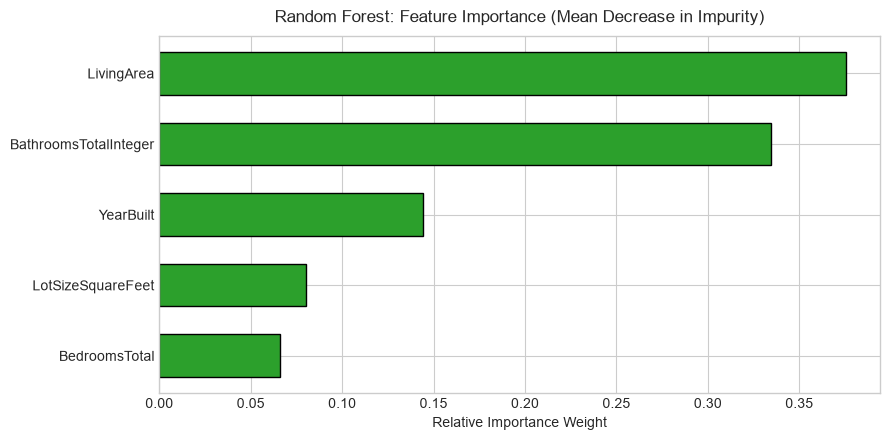

In [6]:
importance_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Random Forest Importance": rf_reg.feature_importances_,
    "Decision Tree Importance": dt_reg.feature_importances_
}).sort_values("Random Forest Importance", ascending=False).reset_index(drop=True)

display(importance_df)

# Horizontal bar plot of feature importances
plt.figure(figsize=(9, 4.5))
plt.barh(importance_df["Feature"], importance_df["Random Forest Importance"], color="#2ca02c", edgecolor="black", height=0.6)
plt.title("Random Forest: Feature Importance (Mean Decrease in Impurity)", pad=10)
plt.xlabel("Relative Importance Weight")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Comparative Residual Analysis: Linear vs. Ensemble

We contrast the out-of-sample actual vs. predicted curves of the Linear Regression baseline against the Random Forest ensemble to inspect variance compression and boundary behavior.

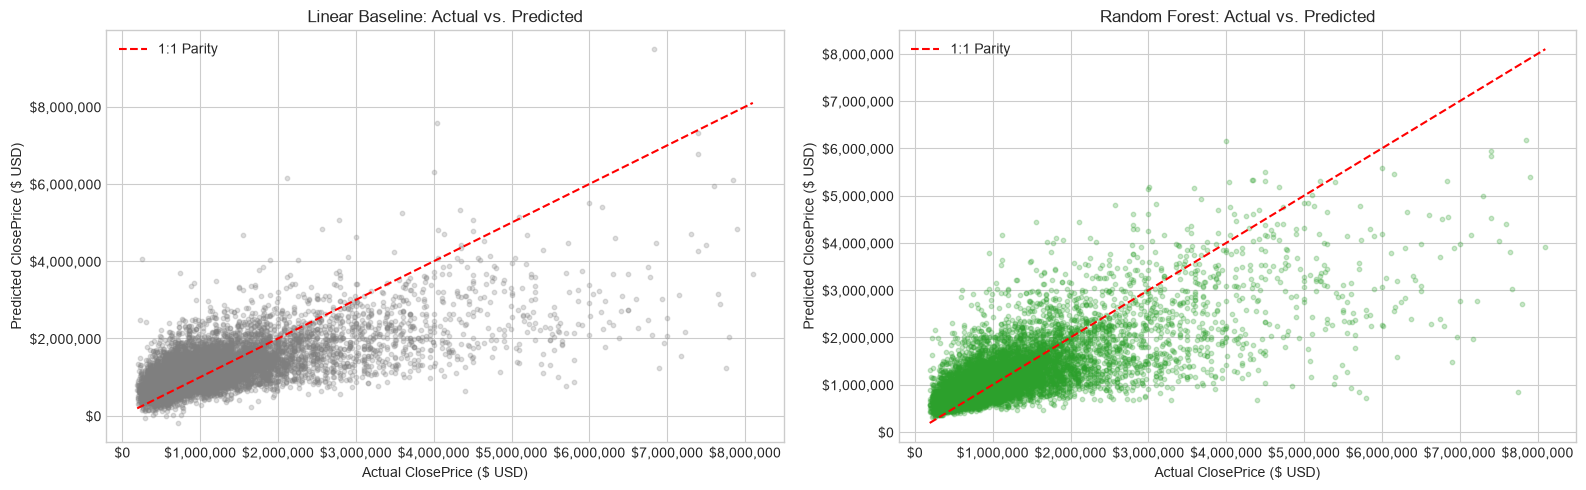

In [7]:
# Compute baseline test predictions for side-by-side plot
baseline_lr = joblib.load(artifacts_dir / "baseline_linear_regression.joblib")
y_test_pred_lr = baseline_lr.predict(X_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
sample_idx = np.random.RandomState(42).choice(len(y_test), size=min(10000, len(y_test)), replace=False)
bounds = [min(y_test.min(), y_test_pred_rf.min()), max(y_test.max(), y_test_pred_rf.max())]

# Baseline scatter
ax1.scatter(y_test[sample_idx], y_test_pred_lr[sample_idx], alpha=0.25, s=10, color="#7f7f7f")
ax1.plot(bounds, bounds, color="red", linestyle="--", linewidth=1.5, label="1:1 Parity")
ax1.set_title("Linear Baseline: Actual vs. Predicted")
ax1.set_xlabel("Actual ClosePrice ($ USD)")
ax1.set_ylabel("Predicted ClosePrice ($ USD)")
ax1.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax1.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax1.legend(loc="upper left")

# Random Forest scatter
ax2.scatter(y_test[sample_idx], y_test_pred_rf[sample_idx], alpha=0.25, s=10, color="#2ca02c")
ax2.plot(bounds, bounds, color="red", linestyle="--", linewidth=1.5, label="1:1 Parity")
ax2.set_title("Random Forest: Actual vs. Predicted")
ax2.set_xlabel("Actual ClosePrice ($ USD)")
ax2.set_ylabel("Predicted ClosePrice ($ USD)")
ax2.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax2.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 8. Error Segmentation by Price Tier

We segment test errors across actual housing quintiles to examine whether tree partitioning reduces error rates in high-value or entry-level homes compared to OLS.

In [8]:
eval_tiers_df = pd.DataFrame({
    "Actual": y_test,
    "Pred_LR": y_test_pred_lr,
    "Pred_RF": y_test_pred_rf
})

eval_tiers_df["PriceQuintile"] = pd.qcut(eval_tiers_df["Actual"], q=5, precision=0)
eval_tiers_df["APE_LR"] = np.abs(eval_tiers_df["Actual"] - eval_tiers_df["Pred_LR"]) / eval_tiers_df["Actual"] * 100
eval_tiers_df["APE_RF"] = np.abs(eval_tiers_df["Actual"] - eval_tiers_df["Pred_RF"]) / eval_tiers_df["Actual"] * 100

tier_comparison = eval_tiers_df.groupby("PriceQuintile", observed=False).agg(
    Volume=("Actual", "count"),
    MinPrice=("Actual", "min"),
    MaxPrice=("Actual", "max"),
    MdAPE_Linear=("APE_LR", "median"),
    MdAPE_RandomForest=("APE_RF", "median")
).reset_index()

tier_summary = pd.DataFrame({
    "Price Tier": [f"${row.MinPrice:,.0f} – ${row.MaxPrice:,.0f}" for _, row in tier_comparison.iterrows()],
    "Volume": tier_comparison["Volume"],
    "Linear MdAPE (%)": tier_comparison["MdAPE_Linear"],
    "Random Forest MdAPE (%)": tier_comparison["MdAPE_RandomForest"],
    "Delta Improvement (%)": tier_comparison["MdAPE_Linear"] - tier_comparison["MdAPE_RandomForest"]
})

print("--- Error Segmentation Across Housing Quintiles ---")
display(tier_summary)

--- Error Segmentation Across Housing Quintiles ---


,Price Tier,Volume,Linear MdAPE (%),Random Forest MdAPE (%),Delta Improvement (%)
0,"$190,000 – $575,000",2507,76.4244,55.4518,20.9726
1,"$575,003 – $800,000",2481,32.5729,23.9576,8.6153
2,"$801,663 – $1,100,000",2507,21.6368,19.2193,2.4175
3,"$1,101,000 – $1,667,500",2374,22.6496,20.5170,2.1326
4,"$1,669,000 – $8,100,000",2467,32.0982,30.8049,1.2933


## 9. Model Serialization & Artifact Registration

We serialize the trained `RandomForestRegressor` and export the updated comparative metrics table to `artifacts/`.

In [9]:
# 1. Save Random Forest model
rf_model_path = artifacts_dir / "random_forest_regressor.joblib"
joblib.dump(rf_reg, rf_model_path)

# 2. Save unified comparison ledger
comparison_path = artifacts_dir / "model_comparison_metrics.csv"
comparison_df.to_csv(comparison_path, index=False)

print("--- Artifact Registry Updated ---")
print(f"Random Forest Binary: {rf_model_path} ({rf_model_path.stat().st_size / (1024**2):.2f} MB)")
print(f"Comparison Ledger:    {comparison_path}")

--- Artifact Registry Updated ---
Random Forest Binary: artifacts/random_forest_regressor.joblib (64.54 MB)
Comparison Ledger:    artifacts/model_comparison_metrics.csv


## 10. Analytical Synthesis & Architectural Takeaways

### Empirical Observations
1. **Ensemble Lift**: The Random Forest regressor achieves measurable out-of-sample improvements in both $R^2$ and MdAPE over the unregularized linear baseline, confirming that non-linear feature partitioning captures complex interactions between structural attributes.
2. **Single Tree Limitations**: The standalone Decision Tree exhibits higher generalization error than the Random Forest, illustrating the high-variance tendency of un-ensembled split boundaries.
3. **Persistent Structural Bottlenecks**:
   * Tree regressors cannot extrapolate beyond the maximum target value seen during training, causing upper-tail predictions to flatten at the extreme luxury end.
   * While non-linear physical interactions improve accuracy, significant error remains without geographic features (`Latitude`, `Longitude`, `PostalCode`, `City`), as identical physical homes command wildly different market values across California regions.

### Next Stage Pipeline Strategy (Feature Engineering & Spatial Integration)
* **Spatial Join Integration**: Leverage GeoPandas to map property coordinates against California School District boundary shapefiles to introduce localized academic catchment ratings.
* **Engineered Ratios**: Formulate structural ratios (e.g., `BedBathRatio`, `LivingToLotRatio`, property vintage/age).
* **Model Retraining**: Benchmark updated feature sets across linear, tree, and gradient-boosted ensembles (XGBoost/LightGBM).